In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train=pd.read_csv("../data/raw/Train.csv")
test=pd.read_csv("../data/raw/Test.csv")
sample_submission=pd.read_csv("../data/raw/SampleSubmission.csv")


In [3]:
train.head()

,sample_id,time,lat,lon,TWS_t,SPEI_01_t,SPEI_03_t,SPEI_06_t,SPEI_12_t,SOIL_MOISTURE_t,month_sin,month_cos,target
0,20020501_-55.5_-68.5,2002-05-01,-55.5,-68.5,0.876217,-1.584223,-1.701647,-2.015145,-1.912281,-1.827801,0.5,-0.866025,0.207665
1,20020501_-55.5_-67.5,2002-05-01,-55.5,-67.5,0.998124,-1.507424,-1.569591,-2.458965,-2.172938,-2.093158,0.5,-0.866025,0.634465
2,20020501_-54.5_-71.5,2002-05-01,-54.5,-71.5,0.813429,-1.473106,-1.151013,-0.524714,-0.908085,-0.932320,0.5,-0.866025,-0.337083
3,20020501_-54.5_-70.5,2002-05-01,-54.5,-70.5,0.841872,-1.460751,-1.487956,-0.588550,-0.936815,-0.928435,0.5,-0.866025,-0.148142
4,20020501_-54.5_-69.5,2002-05-01,-54.5,-69.5,0.872800,-1.275593,-1.729794,-0.243831,-0.870009,-1.053660,0.5,-0.866025,0.089539


In [4]:
train.shape

(2154021, 13)

In [5]:
train.columns

Index(['sample_id', 'time', 'lat', 'lon', 'TWS_t', 'SPEI_01_t', 'SPEI_03_t',
       'SPEI_06_t', 'SPEI_12_t', 'SOIL_MOISTURE_t', 'month_sin', 'month_cos',
       'target'],
      dtype='str')

In [6]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 2154021 entries, 0 to 2154020
Data columns (total 13 columns):
 #   Column           Dtype  
---  ------           -----  
 0   sample_id        str    
 1   time             str    
 2   lat              float64
 3   lon              float64
 4   TWS_t            float64
 5   SPEI_01_t        float64
 6   SPEI_03_t        float64
 7   SPEI_06_t        float64
 8   SPEI_12_t        float64
 9   SOIL_MOISTURE_t  float64
 10  month_sin        float64
 11  month_cos        float64
 12  target           float64
dtypes: float64(11), str(2)
memory usage: 213.6 MB


In [7]:
train.describe()

,lat,lon,TWS_t,SPEI_01_t,SPEI_03_t,SPEI_06_t,SPEI_12_t,SOIL_MOISTURE_t,month_sin,month_cos,target
count,2.154021e+06,2.154021e+06,2.154021e+06,2.154021e+06,2.154021e+06,2.154021e+06,2.154021e+06,2.154021e+06,2.154021e+06,2.154021e+06,2.154021e+06
mean,3.308280e+01,1.751352e+01,1.169951e-01,-3.036841e-02,-5.532355e-02,-7.056598e-02,-9.326984e-02,7.793249e-04,1.119258e-02,2.550246e-02,1.125038e-01
std,3.218869e+01,8.531941e+01,9.130253e-01,9.565037e-01,9.443981e-01,9.398898e-01,9.306511e-01,7.874561e-01,7.044940e-01,7.091636e-01,9.119618e-01
min,-5.550000e+01,-1.795000e+02,-3.968328e+00,-4.247924e+00,-5.225329e+00,-4.383301e+00,-4.622383e+00,-5.107245e+00,-1.000000e+00,-1.000000e+00,-3.968328e+00
25%,9.500000e+00,-6.350000e+01,-5.267003e-01,-7.485308e-01,-7.611284e-01,-7.695646e-01,-7.793398e-01,-4.451756e-01,-5.000000e-01,-5.000000e-01,-5.294420e-01
50%,4.050000e+01,2.750000e+01,1.315323e-01,-5.587444e-02,-7.610958e-02,-8.940844e-02,-1.134589e-01,6.545279e-04,1.224647e-16,6.123234e-17,1.273017e-01
75%,5.950000e+01,9.050000e+01,7.858112e-01,6.660710e-01,6.313823e-01,6.098065e-01,5.749569e-01,5.026704e-01,5.000000e-01,8.660254e-01,7.807068e-01
max,8.350000e+01,1.795000e+02,4.057275e+00,3.475902e+00,4.177270e+00,4.850391e+00,3.764673e+00,5.385165e+00,1.000000e+00,1.000000e+00,4.057275e+00


In [8]:
test.shape

(280961, 13)

In [9]:
test.head()

,ID,time,lat,lon,TWS_t,SPEI_01_t,SPEI_03_t,SPEI_06_t,SPEI_12_t,SOIL_MOISTURE_t,month_sin,month_cos,TWS_t_masked
0,20150901_-55.5_-68.5,2015-09-01,-55.5,-68.5,-0.373966,-0.024582,0.958610,0.549351,1.264457,-0.474105,-1.0,-1.836970e-16,False
1,20150901_-55.5_-67.5,2015-09-01,-55.5,-67.5,-0.530701,-0.049041,1.070304,0.526642,1.267029,-0.217645,-1.0,-1.836970e-16,False
2,20150901_-54.5_-71.5,2015-09-01,-54.5,-71.5,0.531723,0.661190,1.189847,0.924421,0.851582,-0.574531,-1.0,-1.836970e-16,False
3,20150901_-54.5_-70.5,2015-09-01,-54.5,-70.5,0.310179,0.894951,1.310615,1.090452,1.161290,-1.140090,-1.0,-1.836970e-16,False
4,20150901_-54.5_-69.5,2015-09-01,-54.5,-69.5,0.110071,1.167738,1.462231,1.291645,1.247388,-1.581409,-1.0,-1.836970e-16,False


In [10]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 280961 entries, 0 to 280960
Data columns (total 13 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   ID               280961 non-null  str    
 1   time             280961 non-null  str    
 2   lat              280961 non-null  float64
 3   lon              280961 non-null  float64
 4   TWS_t            94048 non-null   float64
 5   SPEI_01_t        280961 non-null  float64
 6   SPEI_03_t        280961 non-null  float64
 7   SPEI_06_t        280961 non-null  float64
 8   SPEI_12_t        280961 non-null  float64
 9   SOIL_MOISTURE_t  280961 non-null  float64
 10  month_sin        280961 non-null  float64
 11  month_cos        280961 non-null  float64
 12  TWS_t_masked     280961 non-null  bool   
dtypes: bool(1), float64(10), str(2)
memory usage: 26.0 MB


In [11]:
test.describe()

,lat,lon,TWS_t,SPEI_01_t,SPEI_03_t,SPEI_06_t,SPEI_12_t,SOIL_MOISTURE_t,month_sin,month_cos
count,280961.000000,280961.000000,94048.000000,280961.000000,280961.000000,280961.000000,280961.000000,280961.000000,2.809610e+05,2.809610e+05
mean,33.080152,17.541554,-0.051049,-0.009498,-0.034009,-0.056483,-0.114175,0.031105,9.780046e-02,1.059222e-03
std,32.194181,85.324307,0.957270,0.976780,1.003526,0.998345,0.976346,0.843641,6.802080e-01,7.264672e-01
min,-55.500000,-179.500000,-3.263359,-4.199318,-4.273445,-3.706275,-3.847257,-5.318862,-1.000000e+00,-1.000000e+00
25%,9.500000,-63.500000,-0.674276,-0.747989,-0.791332,-0.817281,-0.861551,-0.419456,-5.000000e-01,-8.660254e-01
50%,40.500000,27.500000,-0.170790,-0.032112,-0.045108,-0.059016,-0.115639,0.058956,1.224647e-16,6.123234e-17
75%,59.500000,90.500000,0.572820,0.706383,0.707291,0.689928,0.621200,0.574705,8.660254e-01,8.660254e-01
max,83.500000,179.500000,3.701359,3.096373,3.309473,2.973456,3.253553,5.334668,1.000000e+00,1.000000e+00


In [12]:
sample_submission.head()

,ID,Target
0,20150901_-55.5_-68.5,0
1,20150901_-55.5_-67.5,0
2,20150901_-54.5_-71.5,0
3,20150901_-54.5_-70.5,0
4,20150901_-54.5_-69.5,0


In [13]:
sample_submission.info()

<class 'pandas.DataFrame'>
RangeIndex: 280961 entries, 0 to 280960
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   ID      280961 non-null  str  
 1   Target  280961 non-null  int64
dtypes: int64(1), str(1)
memory usage: 4.3 MB


In [ ]:
train.isnull().sum()

sample_id          0
time               0
lat                0
lon                0
TWS_t              0
SPEI_01_t          0
SPEI_03_t          0
SPEI_06_t          0
SPEI_12_t          0
SOIL_MOISTURE_t    0
month_sin          0
month_cos          0
target             0
dtype: int64

In [15]:
test.isnull().sum()

ID                      0
time                    0
lat                     0
lon                     0
TWS_t              186913
SPEI_01_t               0
SPEI_03_t               0
SPEI_06_t               0
SPEI_12_t               0
SOIL_MOISTURE_t         0
month_sin               0
month_cos               0
TWS_t_masked            0
dtype: int64

In [17]:
train.nunique()

sample_id          2154021
time                   138
lat                    140
lon                    358
TWS_t              2119538
SPEI_01_t          2117866
SPEI_03_t          2117747
SPEI_06_t          2118182
SPEI_12_t          2118442
SOIL_MOISTURE_t    2101205
month_sin                8
month_cos                8
target             2119440
dtype: int64

In [18]:
missing=train.isnull().sum().sort_values(ascending=False)
missing[missing>0]

Series([], dtype: int64)

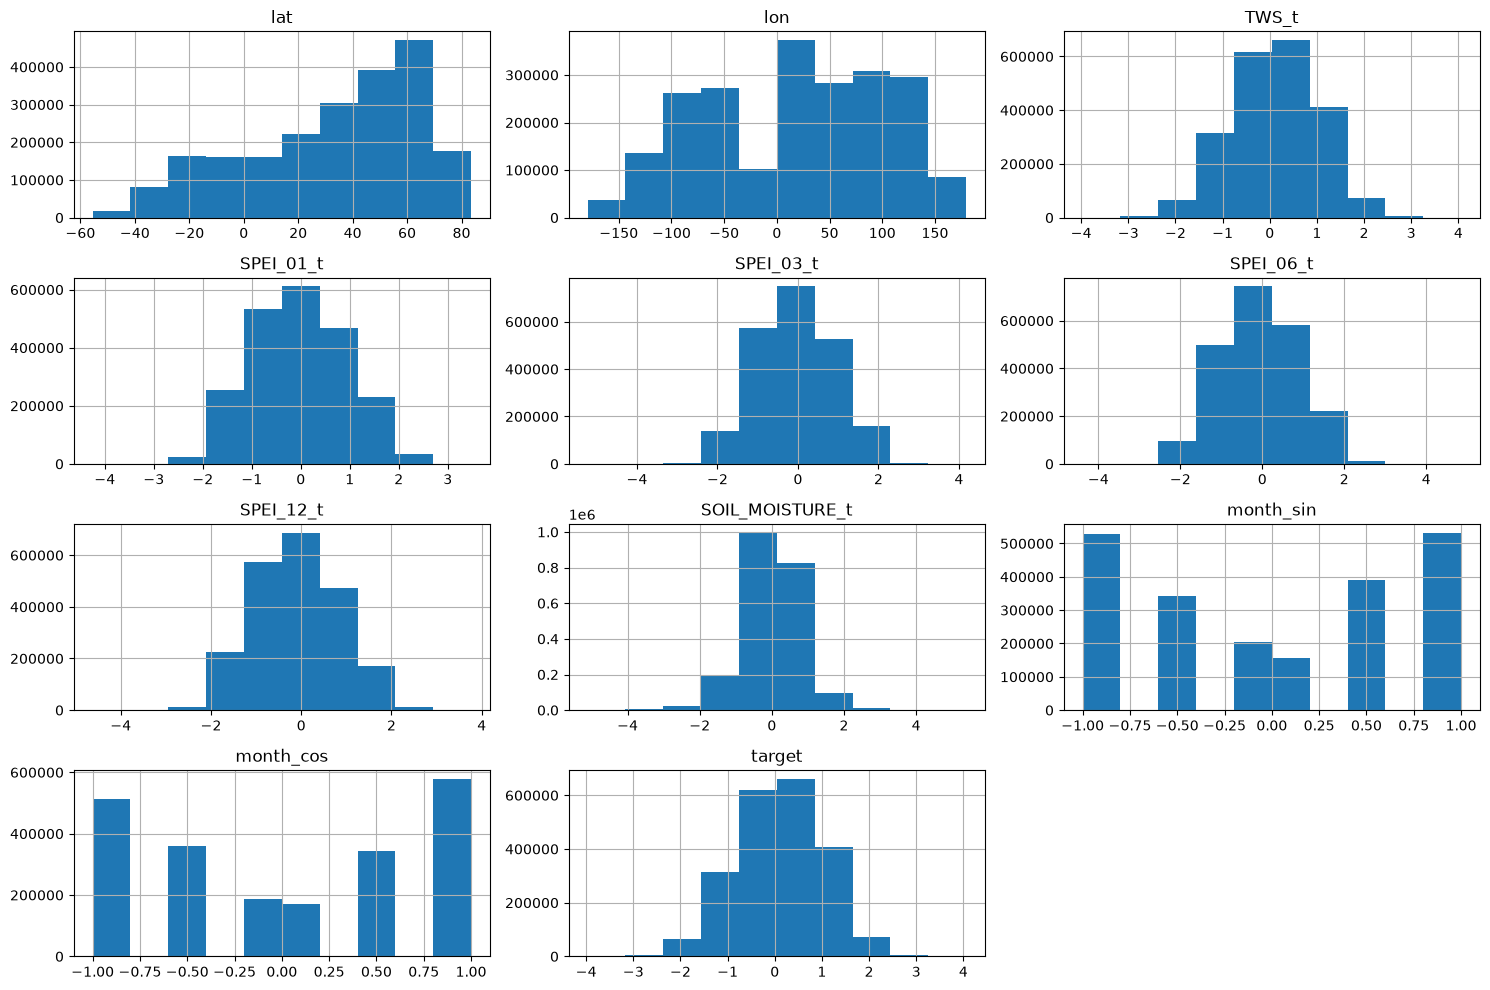

In [21]:
train.hist(figsize=(15,10))
plt.tight_layout()
plt.show()

In [22]:
corr=train.corr(numeric_only=True)

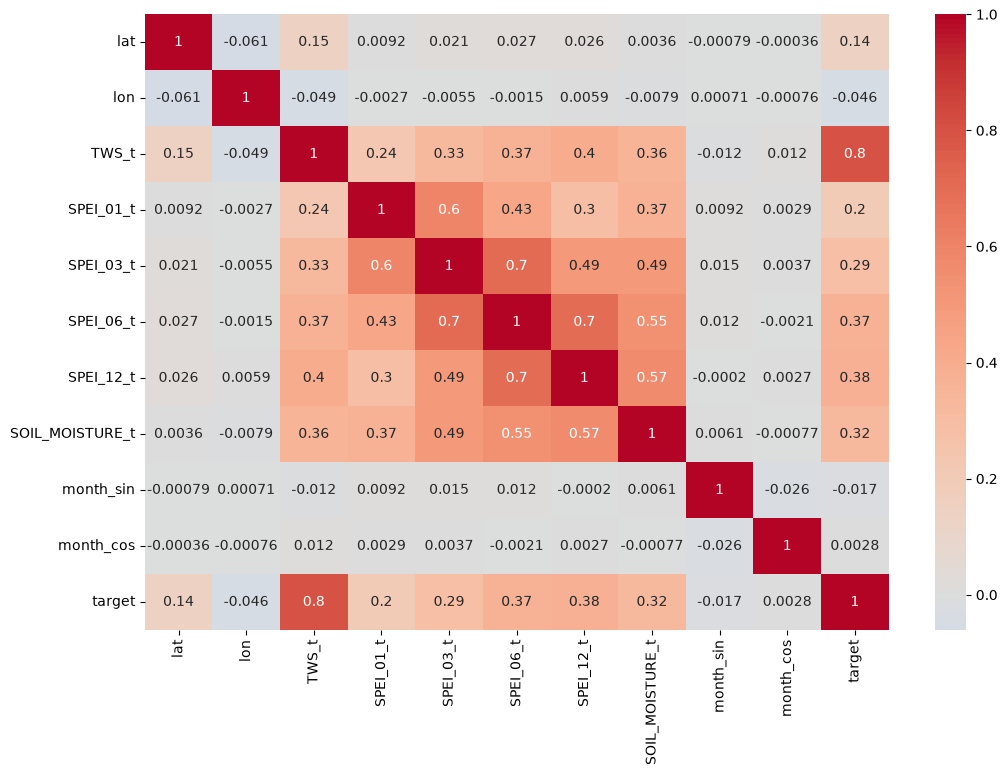

In [ ]:
plt.figure(figsize=(12,8))
sns.heatmap(corr,cmap="coolwarm",center=0,annot=True)#annot matris üzerine sayıları yazdırır ilişkileri anlamak için
plt.show()